# 02b — Validação da Indexação (local)

Confere os índices criados por `scripts/index_embeddings.py` no Elasticsearch local (Docker): contagem de
documentos, norma dos embeddings, buscas manuais e comparação entre modelos.

**Pré-requisito:** `python scripts/index_embeddings.py` executado com o Elasticsearch ativo.
Configure `ES_URL`, `ES_USER` e `ES_PASSWORD` (variáveis de ambiente) se necessário.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# ── Configuração única ───────────────────────────────────────────────
DEVICE = "auto"                     # "cpu" | "cuda" | "auto"
DRIVE_PROJECT_DIR = "MyDrive/tcc"   # pasta do projeto no Google Drive (só Colab)
# ─────────────────────────────────────────────────────────────────────

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive") / DRIVE_PROJECT_DIR
    %pip install -q polars pyarrow matplotlib elasticsearch~=8.15 sentence-transformers tqdm
else:
    PROJECT_ROOT = Path.cwd()

assert (PROJECT_ROOT / "src").exists(), f"Pasta 'src' não encontrada em {PROJECT_ROOT}"
sys.path.insert(0, str(PROJECT_ROOT))

from src.device import build_runtime_config, collect

RUNTIME = build_runtime_config(DEVICE)
print(f"Projeto : {PROJECT_ROOT}")
print(f"Colab   : {IN_COLAB}")
print(f"Device  : {RUNTIME.device} (batch_size={RUNTIME.batch_size}, max_seq_length={RUNTIME.max_seq_length})")

Projeto : c:\Users\Dev\tcc
Colab   : False
Device  : cpu (batch_size=32, max_seq_length=128)


In [2]:
import os

import matplotlib.pyplot as plt
import polars as pl
from elasticsearch import Elasticsearch

from src.elasticsearch.searcher import Searcher, SearchStrategy
from src.models.registry import BM25_INDEX_NAME, list_models
from src.text import prepare_dataframe

PRODUCTS_PATH = PROJECT_ROOT / "data" / "processed" / "products_us.parquet"
REPORT_DIR = PROJECT_ROOT / "results" / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
assert PRODUCTS_PATH.exists(), f"{PRODUCTS_PATH} não encontrado. Execute o notebook 01 primeiro."

ES_URL = [{"host": "localhost", "port": 9200, "scheme": "http"}]
ES_USER = os.environ.get("ES_USER", "elastic")
ES_PASSWORD = os.environ.get("ES_PASSWORD", "meutcc")   # None = sem autenticação
VERIFY_CERTS = False                          # certificado autoassinado do Docker

client_kwargs: dict = {"request_timeout": 60}
if ES_PASSWORD:
    client_kwargs["basic_auth"] = (ES_USER, ES_PASSWORD)
if type(ES_URL) is str and ES_URL.startswith("https"):
    client_kwargs["verify_certs"] = VERIFY_CERTS
es = Elasticsearch(ES_URL, **client_kwargs)

try:
    print("Elasticsearch", es.info()["version"]["number"], "conectado em", ES_URL)
except Exception as exc:
    raise RuntimeError(f"Sem conexão com {ES_URL}: {exc}\nInicie o Elasticsearch (Docker) e confira ES_URL/ES_PASSWORD.") from exc

plt.rcParams["figure.dpi"] = 120

Elasticsearch 8.10.2 conectado em [{'host': 'localhost', 'port': 9200, 'scheme': 'http'}]


A busca híbrida (RRF) exige licença que o plano gratuito não inclui. A célula abaixo ativa a licença trial de 30 dias
no servidor local; em um servidor externo sem a licença, a estratégia `hybrid` falhará no notebook 03.

In [3]:
try:
    es.license.post_start_trial(acknowledge=True)
except Exception as exc:
    print(f"Não foi possível iniciar a licença trial: {exc}")
print("Licença:", es.license.get()["license"]["type"])

Não foi possível iniciar a licença trial: AuthorizationException(403, "{'acknowledged': True, 'trial_was_started': False, 'error_message': 'Operation failed: Trial was already activated.'}")
Licença: trial


## 1. Documentos esperados

In [4]:
expected_docs = prepare_dataframe(pl.read_parquet(PRODUCTS_PATH)).height
print(f"Documentos esperados por índice: {expected_docs:,}")

Documentos esperados por índice: 200,000


## 2. Inventário dos índices

In [5]:
index_names = [cfg.es_index_name for cfg in list_models()] + [BM25_INDEX_NAME]

rows = []
for index_name in index_names:
    if not es.indices.exists(index=index_name):
        rows.append({"index": index_name, "docs": None, "size_gb": None, "ok": False})
        continue
    stats = es.indices.stats(index=index_name)["_all"]["primaries"]
    docs = stats["docs"]["count"]
    rows.append({
        "index": index_name,
        "docs": docs,
        "size_gb": round(stats["store"]["size_in_bytes"] / 1024**3, 2),
        "ok": docs == expected_docs,
    })

inventory = pl.DataFrame(rows, schema={"index": pl.String, "docs": pl.Int64, "size_gb": pl.Float64, "ok": pl.Boolean})
print(f"Documentos esperados por índice: {expected_docs:,}")
inventory

Documentos esperados por índice: 200,000


index,docs,size_gb,ok
str,i64,f64,bool
"""esci-bert-us""",200000,2.95,true
"""esci-roberta-us""",200000,2.96,true
"""esci-modernbert-us""",200000,2.96,true
"""esci-bge-us""",200000,3.9,true
"""esci-rexbert-us""",200000,2.96,true
"""esci-bm25-us""",200000,0.07,true


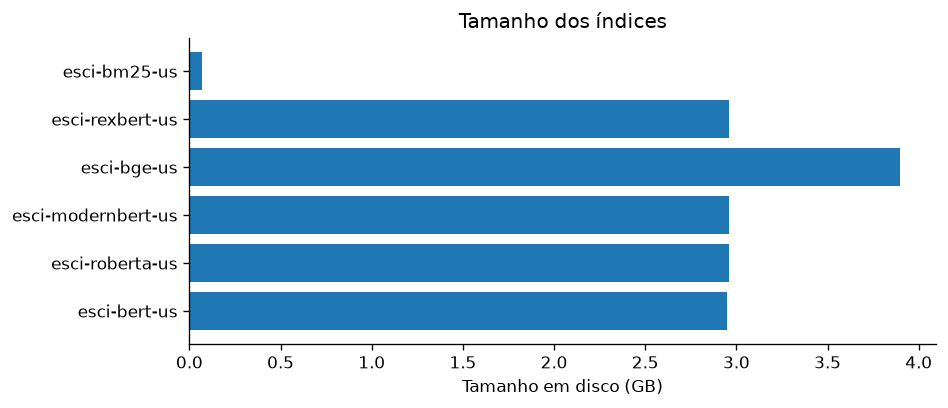

In [6]:
existing = inventory.drop_nulls("size_gb")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(existing["index"].to_list(), existing["size_gb"].to_list(), color="#1f77b4")
ax.set_xlabel("Tamanho em disco (GB)")
ax.set_title("Tamanho dos índices")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(REPORT_DIR / "indexing_sizes.png", bbox_inches="tight")
plt.show()

## 3. Sanidade dos embeddings

In [7]:
N_SAMPLE = 50

norm_rows = []
for cfg in list_models():
    if not es.indices.exists(index=cfg.es_index_name):
        continue
    response = es.search(
        index=cfg.es_index_name,
        size=N_SAMPLE,
        query={"function_score": {"random_score": {}}},
        source=["embedding"],
    )
    vectors = [hit["_source"]["embedding"] for hit in response["hits"]["hits"] if "embedding" in hit["_source"]]
    if not vectors:
        print(f"{cfg.alias}: nenhum embedding retornado em _source")
        continue
    norms = pl.Series([sum(v * v for v in vec) ** 0.5 for vec in vectors])
    norm_rows.append({
        "model": cfg.alias,
        "dim_ok": all(len(vec) == cfg.embedding_dim for vec in vectors),
        "norm_mean": norms.mean(),
        "norm_min": norms.min(),
        "norm_max": norms.max(),
    })

print("Normas L2 esperadas: ~1.0 (normalize_embeddings=True)")
pl.DataFrame(norm_rows).with_columns(pl.col("^norm_.*$").round(6))

Normas L2 esperadas: ~1.0 (normalize_embeddings=True)


model,dim_ok,norm_mean,norm_min,norm_max
str,bool,f64,f64,f64
"""bert""",true,1.0,1.0,1.0
"""roberta""",true,1.0,1.0,1.0
"""modernbert""",true,1.0,1.0,1.0
"""bge""",true,1.0,1.0,1.0
"""rexbert""",true,1.0,1.0,1.0


## 4. Buscas manuais

In [8]:
SAMPLE_MODEL = "bge"
SAMPLE_QUERIES = ["wireless noise cancelling headphones", "running shoes for women", "usb c cable 6ft"]

searcher = Searcher(es, device=RUNTIME.device)

for query in SAMPLE_QUERIES:
    print(f"\n=== {query} ===")
    for strategy in SearchStrategy:
        try:
            hits = searcher.search(SAMPLE_MODEL, query, strategy=strategy, k=3)
        except Exception as exc:
            print(f"[{strategy.value}] erro: {exc}")
            continue
        print(f"[{strategy.value}]")
        for hit in hits:
            print(f"  {hit.rank}. {hit.score:.3f}  {hit.product_title[:90]}")

searcher.unload_model(SAMPLE_MODEL)


=== wireless noise cancelling headphones ===
[bm25]
  1. 87.580  Skullcandy Crusher ANC Personalized Noise Canceling Wireless Headphone - Deep Red
  2. 87.580  JBL TUNE 750BTNC - Wireless Over-Ear Headphones with Noise Cancellation - Blue
  3. 84.135  Wireless Headphones - Premium 2020 - Best Wireless Earbuds - Workout Headphones - Sport He


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[knn]
  1. 0.874  Wireless Headset
  2. 0.849  Bluetooth Headphones
  3. 0.848  Sony Noise Cancelling Headphones WH1000XM2: Over Ear Wireless Bluetooth Headphones with Mi
[hybrid] erro: BadRequestError(400, 'parsing_exception', 'Unknown key for a START_OBJECT in [retriever].')

=== running shoes for women ===
[bm25]
  1. 47.423  Nike Women's Flex Contact Running Shoe
  2. 47.423  Nike Women's Revolution 4 Running Shoe
  3. 47.423  Nike Women's Revolution 4 Running Shoe
[knn]
  1. 0.860  Nike Women's Flex Contact Running Shoe
  2. 0.856  Women's Shoes, Women Running Trainers Lace Up Flat Comfy Fitness Gym Sports Shoes Casual S
  3. 0.852  Nike Women's Revolution 4 Running Shoe
[hybrid] erro: BadRequestError(400, 'parsing_exception', 'Unknown key for a START_OBJECT in [retriever].')

=== usb c cable 6ft ===
[bm25]
  1. 70.230  87W USB-C Power Adapter Charger,with USB-C to USB-C Charge Cable,USB c Charge Cable
  2. 69.875  Xcentz USB Type C Cable, [2 Pack 6ft] USB C Cable, USB C to USB A 

## 5. Comparação entre modelos para uma mesma query

Compara o top-K da busca KNN em cada índice de embedding.

In [9]:
COMPARISON_QUERY = "wireless bluetooth headphones"
K_COMPARE = 5

print(f"Query: '{COMPARISON_QUERY}' — top {K_COMPARE} por modelo (KNN)")
for cfg in list_models():
    if not es.indices.exists(index=cfg.es_index_name):
        print(f"\n[{cfg.alias}] índice não encontrado, pulando.")
        continue
    hits = searcher.search(cfg.alias, COMPARISON_QUERY, strategy=SearchStrategy.KNN, k=K_COMPARE)
    print(f"\n[{cfg.display_name}]")
    for hit in hits:
        print(f"  #{hit.rank}  score={hit.score:.4f}  {hit.product_title[:70]}")
    searcher.unload_model(cfg.alias)

Query: 'wireless bluetooth headphones' — top 5 por modelo (KNN)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



[BERT Base]
  #1  score=0.9826  Bluetooth Headphones
  #2  score=0.9459  Wireless Earbuds Bluetooth 5.0 Headphones
  #3  score=0.9253  Wireless Headset
  #4  score=0.9179  Headphones
  #5  score=0.9141  Wireless Earbuds Bluetooth 5.0 Sports Headphones TWS in-Ear Earphones


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: FacebookAI/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (12 outputs left out)

tokenizer_config.json:   0%|          | 0.00/20.8k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.58M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/693 [00:00<?, ?B/s]


[RexBERT Base]
  #1  score=0.9505  Bluetooth Headphones
  #2  score=0.9368  Wireless Earbuds Bluetooth 5.0 Headphones
  #3  score=0.9363  Bluetooth Headphones, 5.0 MOVONE True Wireless Earbuds Stereo Deep Bas
  #4  score=0.9316  shlutesoy Universal 3.5mm Plug Wired Clip On Ear Sports Earphone Heavy
  #5  score=0.9308  Wireless Earbuds 2020 New for Apple Airpods Pro 3 iPhone Android Touch


## 6. Checklist final

In [10]:
print("CHECKLIST DE VALIDAÇÃO DA INDEXAÇÃO")
print("=" * 55)
for row in inventory.iter_rows(named=True):
    icon = "OK  " if row["ok"] else "FALHA"
    size = f"{row['size_gb']:.2f} GB" if row["size_gb"] is not None else "N/A"
    docs = f"{row['docs']:,}" if row["docs"] is not None else "N/A"
    print(f"  [{icon}] {row['index']:<25} docs={docs:<10} tamanho={size}")

if inventory["ok"].all():
    print("\nTodos os índices estão corretos. Prossiga para o notebook 03 (avaliação).")
else:
    print("\nHá índices ausentes ou incompletos. Ajuste MODELS/OVERWRITE e reexecute a seção 3.")

CHECKLIST DE VALIDAÇÃO DA INDEXAÇÃO
  [OK  ] esci-bert-us              docs=200,000    tamanho=2.95 GB
  [OK  ] esci-roberta-us           docs=200,000    tamanho=2.96 GB
  [OK  ] esci-modernbert-us        docs=200,000    tamanho=2.96 GB
  [OK  ] esci-bge-us               docs=200,000    tamanho=3.90 GB
  [OK  ] esci-rexbert-us           docs=200,000    tamanho=2.96 GB
  [OK  ] esci-bm25-us              docs=200,000    tamanho=0.07 GB

Todos os índices estão corretos. Prossiga para o notebook 03 (avaliação).
